<a href="https://colab.research.google.com/github/Uriels28/Hands-on-4-The-Perceptron/blob/main/tutorial_perceptron_iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial: Implementación de un Perceptrón en Python

**Objetivo:** implementar y evaluar un Perceptrón usando `scikit-learn` como parte de un Pipeline de Machine Learning.

En este ejemplo clasificaremos flores Iris en dos especies: *setosa* y *versicolor*, usando la longitud y anchura del sépalo. El problema es binario y permite visualizar los datos en un scatter plot.

## 1. Fundamentos teóricos del Perceptrón

El Perceptrón es uno de los modelos más sencillos de una neurona artificial. Fue propuesto por Frank Rosenblatt en 1957. Se utiliza para clasificación supervisada: aprende a asignar una clase a una observación a partir de sus características.

El modelo calcula una suma ponderada de las entradas y un sesgo. Después aplica una función de activación escalón para decidir la clase. Durante el entrenamiento ajusta sus pesos cuando comete una clasificación incorrecta.

**Limitación:** el Perceptrón clásico converge si los datos son linealmente separables. No puede resolver por sí solo problemas que no puedan separarse mediante una frontera lineal, como XOR.

## 2. Modelo matemático y analítico

Para una observación con características $x_1, x_2, ..., x_n$, el Perceptrón calcula:

$$z = w_1x_1 + w_2x_2 + ... + w_nx_n + b$$

La predicción se obtiene con una función escalón:

$$\hat{y} = \begin{cases}1 & z \geq 0\0 & z < 0\\end{cases}$$

Donde $w_i$ son los pesos, $b$ es el sesgo, $x_i$ son las características y $\hat{y}$ es la clase predicha.

Si la predicción es incorrecta, se actualizan los parámetros con:

$$w_i^{nuevo} = w_i^{anterior} + \eta(y-\hat{y})x_i$$

$$b^{nuevo} = b^{anterior} + \eta(y-\hat{y})$$

$\eta$ representa la tasa de aprendizaje. En `scikit-learn`, el algoritmo realiza estas actualizaciones internamente durante `fit()`.

## 3. Pipeline de Machine Learning

El flujo que seguiremos es: recolección de datos → descripción y análisis → visualización → preparación → separación entrenamiento/prueba → entrenamiento → predicción → evaluación. Cada etapa se explica y ejecuta por separado.

## 4. Recolección de datos

Usaremos el dataset Iris que se incluye en `scikit-learn`. No es necesario descargar un archivo externo; la librería proporciona los datos para fines educativos.

In [1]:
# Importamos pandas para organizar los datos en una tabla.
import pandas as pd

# Importamos numpy para operaciones numéricas.
import numpy as np

# Importamos matplotlib para crear gráficas.
import matplotlib.pyplot as plt

# Importamos seaborn para mejorar la visualización estadística.
import seaborn as sns

# Importamos el dataset Iris desde scikit-learn.
from sklearn.datasets import load_iris

# Importamos la clase Perceptron que implementa el algoritmo.
from sklearn.linear_model import Perceptron

# Importamos herramientas para dividir los datos y escalar características.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Importamos métricas para evaluar el modelo.
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Cargamos el dataset Iris como un objeto de scikit-learn.
iris = load_iris()

# Creamos un DataFrame con los datos de las características y sus nombres.
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Agregamos una columna con el número de clase de cada flor.
df['target'] = iris.target

# Agregamos una columna con el nombre legible de la especie.
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

# Mostramos las primeras cinco filas para comprobar que se cargaron los datos.
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 5. Descripción y análisis del dataset

Iris contiene 150 observaciones, cuatro características numéricas y tres especies. Para este tutorial seleccionaremos solo las primeras dos especies, *setosa* y *versicolor*, y dos características: longitud y anchura del sépalo. Esto convierte el ejemplo en una clasificación binaria y permite mostrar los datos en un plano.

In [2]:
# Mostramos la cantidad de filas y columnas del dataset original.
print('Dimensiones del dataset:', df.shape)

# Mostramos los tipos de datos y si existen valores nulos.
df.info()

# Calculamos estadísticas descriptivas de las características numéricas.
df.describe()

Dimensiones del dataset: (150, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [3]:
# Seleccionamos únicamente las especies setosa (0) y versicolor (1).
df_binario = df[df['target'].isin([0, 1])].copy()

# Elegimos dos características para que la clasificación se pueda graficar.
caracteristicas = ['sepal length (cm)', 'sepal width (cm)']

# Mostramos cuántas observaciones hay por especie en el conjunto seleccionado.
print(df_binario['species'].value_counts())

# Revisamos si hay valores nulos en las columnas seleccionadas.
print('Valores nulos:', df_binario[caracteristicas + ['target']].isnull().sum().sum())

species
setosa        50
versicolor    50
Name: count, dtype: int64
Valores nulos: 0


## 6. Scatter Plot

El scatter plot permite observar la distribución de las observaciones según las dos características seleccionadas. Cada punto representa una flor y el color representa su especie.

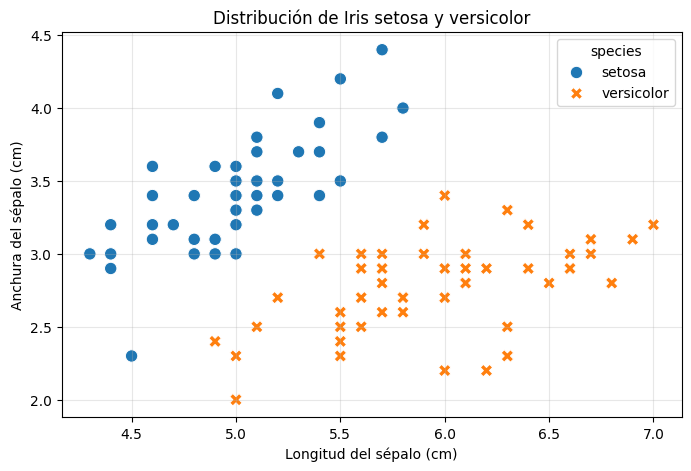

In [4]:
# Creamos un scatter plot con longitud y anchura del sépalo.
plt.figure(figsize=(8, 5))  # Definimos el tamaño de la figura.

sns.scatterplot(
    data=df_binario,  # Indicamos el DataFrame que contiene los datos.
    x=caracteristicas[0],  # Usamos longitud del sépalo en el eje X.
    y=caracteristicas[1],  # Usamos anchura del sépalo en el eje Y.
    hue='species',  # Asignamos un color distinto a cada especie.
    style='species',  # Usamos marcadores distintos por especie.
    s=80  # Definimos el tamaño de los puntos.
)

plt.title('Distribución de Iris setosa y versicolor')  # Agregamos el título.
plt.xlabel('Longitud del sépalo (cm)')  # Etiquetamos el eje X.
plt.ylabel('Anchura del sépalo (cm)')  # Etiquetamos el eje Y.
plt.grid(True, alpha=0.3)  # Agregamos una cuadrícula tenue.
plt.show()  # Mostramos la gráfica.

## 7. Preparación de los datos

Separamos las características (`X`) de la etiqueta (`y`). En este caso, `X` contiene las dos medidas del sépalo y `y` contiene la especie codificada como 0 o 1. Después dividimos los datos en entrenamiento y prueba. El conjunto de prueba se reserva para evaluar el modelo con datos que no vio durante el entrenamiento.

In [5]:
# Seleccionamos las dos características y las guardamos como matriz X.
X = df_binario[caracteristicas].to_numpy()

# Seleccionamos la clase objetivo y la guardamos como vector y.
y = df_binario['target'].to_numpy()

# Dividimos los datos: 80% entrenamiento y 20% prueba.
# stratify mantiene la proporción de clases en ambos conjuntos.
X_train, X_test, y_train, y_test = train_test_split(
    X,  # Datos de entrada.
    y,  # Etiquetas.
    test_size=0.20,  # Reservamos 20% para prueba.
    random_state=42,  # Fijamos la semilla para reproducibilidad.
    stratify=y  # Conservamos la proporción de las clases.
)

# Creamos un escalador para estandarizar las características.
escalador = StandardScaler()

# Ajustamos el escalador únicamente con los datos de entrenamiento.
X_train_scaled = escalador.fit_transform(X_train)

# Aplicamos la misma transformación al conjunto de prueba.
X_test_scaled = escalador.transform(X_test)

# Mostramos las dimensiones para verificar la división.
print('X_train:', X_train_scaled.shape)
print('X_test:', X_test_scaled.shape)

X_train: (80, 2)
X_test: (20, 2)


## 8. Creación del modelo Perceptrón

Configuramos el modelo. `max_iter` indica el máximo de pasadas sobre los datos y `eta0` es la tasa de aprendizaje. `random_state` permite repetir el experimento con los mismos resultados.

In [6]:
# Creamos el modelo Perceptrón con sus parámetros.
modelo = Perceptron(
    max_iter=1000,  # Número máximo de épocas de entrenamiento.
    eta0=0.1,  # Tasa de aprendizaje inicial.
    random_state=42  # Semilla para reproducibilidad.
)

# Mostramos la configuración del modelo.
print(modelo)

Perceptron(eta0=0.1, random_state=42)


## 9. Entrenamiento

El método `fit()` entrena el Perceptrón utilizando las características y etiquetas del conjunto de entrenamiento. Durante este proceso, el algoritmo ajusta los pesos y el sesgo.

In [7]:
# Entrenamos el modelo con los datos de entrenamiento escalados.
modelo.fit(X_train_scaled, y_train)

# Mostramos los pesos aprendidos por el modelo.
print('Pesos:', modelo.coef_)

# Mostramos el sesgo aprendido.
print('Sesgo:', modelo.intercept_)

Pesos: [[ 0.36356932 -0.16152271]]
Sesgo: [0.1]


## 10. Predicción

Una vez entrenado, usamos `predict()` para obtener la clase que el modelo asigna a cada observación del conjunto de prueba.

In [8]:
# Generamos predicciones para las observaciones de prueba.
y_pred = modelo.predict(X_test_scaled)

# Mostramos las primeras predicciones y sus clases reales.
print('Predicciones:', y_pred[:10])
print('Clases reales:', y_test[:10])

Predicciones: [0 1 1 1 0 0 0 1 1 0]
Clases reales: [1 1 1 1 0 0 0 1 0 0]


## 11. Evaluación del modelo (métricas)

Evaluamos el desempeño comparando las predicciones con las clases reales. Usaremos:

- **Accuracy (exactitud):** proporción de predicciones correctas.
- **Matriz de confusión:** cantidad de aciertos y errores por clase.
- **Precision, recall y F1-score:** resumen el desempeño para cada clase.

Estas métricas ayudan a entender el resultado más allá de una sola cifra.

In [9]:
# Calculamos la exactitud general del modelo.
accuracy = accuracy_score(y_test, y_pred)

# Imprimimos la exactitud en porcentaje.
print(f'Accuracy: {accuracy:.2%}')

# Mostramos la matriz de confusión.
matriz = confusion_matrix(y_test, y_pred)
print('Matriz de confusión:')
print(matriz)

# Mostramos precision, recall, f1-score y soporte por clase.
print(classification_report(
    y_test,  # Etiquetas reales.
    y_pred,  # Etiquetas predichas.
    target_names=iris.target_names[:2]  # Nombres de las dos clases.
))

Accuracy: 90.00%
Matriz de confusión:
[[9 1]
 [1 9]]
              precision    recall  f1-score   support

      setosa       0.90      0.90      0.90        10
  versicolor       0.90      0.90      0.90        10

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.90        20
weighted avg       0.90      0.90      0.90        20



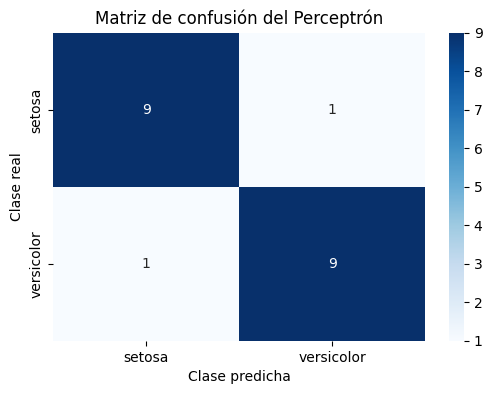

In [10]:
# Dibujamos la matriz de confusión como un mapa de calor.
plt.figure(figsize=(6, 4))  # Definimos el tamaño de la figura.

sns.heatmap(
    matriz,  # Datos de la matriz.
    annot=True,  # Mostramos los valores dentro de las celdas.
    fmt='d',  # Mostramos los valores como enteros.
    cmap='Blues',  # Elegimos una paleta de colores.
    xticklabels=iris.target_names[:2],  # Etiquetas del eje X.
    yticklabels=iris.target_names[:2]  # Etiquetas del eje Y.
)

plt.xlabel('Clase predicha')  # Etiquetamos el eje horizontal.
plt.ylabel('Clase real')  # Etiquetamos el eje vertical.
plt.title('Matriz de confusión del Perceptrón')  # Agregamos título.
plt.show()  # Mostramos la gráfica.

## 12. Visualización de la frontera de decisión

La frontera de decisión muestra cómo separa el modelo las dos clases en el plano formado por las características. La región de fondo indica la clase que el modelo predice para cada zona.

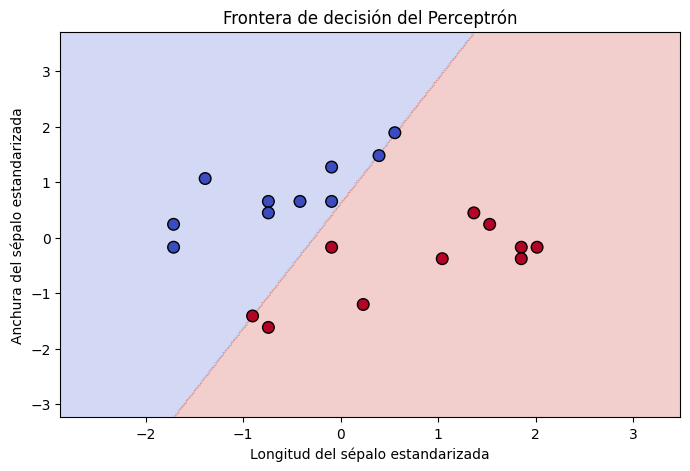

In [11]:
# Definimos el rango horizontal y vertical para dibujar el plano.
x_min, x_max = X_train_scaled[:, 0].min() - 1, X_train_scaled[:, 0].max() + 1
y_min, y_max = X_train_scaled[:, 1].min() - 1, X_train_scaled[:, 1].max() + 1

# Creamos una cuadrícula de puntos para evaluar la predicción del modelo.
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),  # Valores del eje X.
    np.arange(y_min, y_max, 0.02)  # Valores del eje Y.
)

# Convertimos la cuadrícula en una matriz de pares de características.
rejilla = np.c_[xx.ravel(), yy.ravel()]

# Predecimos la clase para cada punto de la cuadrícula.
Z = modelo.predict(rejilla)

# Reconvertimos las predicciones a la forma de la cuadrícula.
Z = Z.reshape(xx.shape)

# Dibujamos las regiones de decisión.
plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, alpha=0.25, cmap='coolwarm')

# Dibujamos los datos de prueba por clase.
plt.scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], c=y_test, cmap='coolwarm', edgecolors='k', s=70)

plt.title('Frontera de decisión del Perceptrón')
plt.xlabel('Longitud del sépalo estandarizada')
plt.ylabel('Anchura del sépalo estandarizada')
plt.show()

## 13. Conclusiones

En este tutorial se implementó un Perceptrón para clasificar dos especies del dataset Iris. Se siguieron las etapas principales del Pipeline de Machine Learning: carga de datos, análisis, visualización, preparación, división, entrenamiento, predicción y evaluación.

El modelo permite observar cómo una técnica de clasificación supervisada aprende una frontera lineal a partir de ejemplos. Su desempeño se revisó mediante accuracy, matriz de confusión y métricas por clase.

**Conclusión final:** el Perceptrón es un modelo sencillo y útil para comprender los fundamentos de la clasificación. Sin embargo, su capacidad está limitada a fronteras lineales, por lo que en problemas más complejos pueden ser necesarias otras técnicas.